In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

In [2]:
#Veri setini düzenle yükle
mist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mist.load_data()

In [3]:
#veriyi normalleşştir
x_train = x_train / 255.0
x_test = x_test / 255.0

In [4]:
#veriyi modelin beklediği şekle dönüştür
x_train = x_train.reshape(x_train.shape[0], 28, 28, 1)
x_test = x_test.reshape(x_test.shape[0], 28, 28, 1)

In [5]:
#CNN modeli oluştur
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

In [6]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(x_train, y_train, epochs=5, validation_data=(x_test, y_test))

Epoch 1/5
1875/1875 [==============================] - 10s 5ms/step - loss: 0.1377 - accuracy: 0.9583 - val_loss: 0.0625 - val_accuracy: 0.9802
Epoch 2/5
1875/1875 [==============================] - 10s 6ms/step - loss: 0.0463 - accuracy: 0.9855 - val_loss: 0.0405 - val_accuracy: 0.9870
Epoch 3/5
1875/1875 [==============================] - 10s 6ms/step - loss: 0.0315 - accuracy: 0.9902 - val_loss: 0.0325 - val_accuracy: 0.9898
Epoch 4/5
1875/1875 [==============================] - 10s 5ms/step - loss: 0.0250 - accuracy: 0.9921 - val_loss: 0.0320 - val_accuracy: 0.9899
Epoch 5/5
1875/1875 [==============================] - 9s 5ms/step - loss: 0.0176 - accuracy: 0.9948 - val_loss: 0.0317 - val_accuracy: 0.9907


313/313 [==============================] - 1s 3ms/step


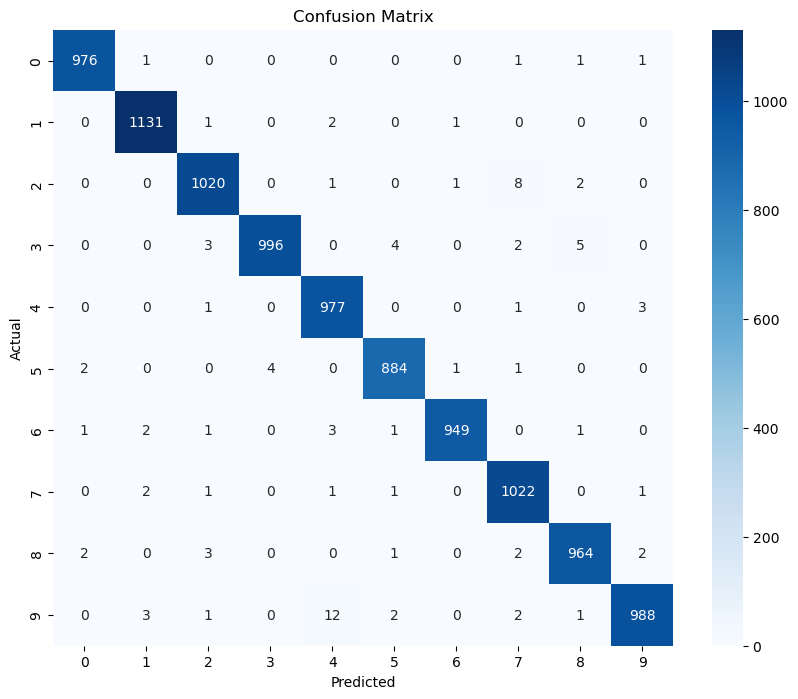

              precision    recall  f1-score   support

           0     0.9949    0.9959    0.9954       980
           1     0.9930    0.9965    0.9947      1135
           2     0.9893    0.9884    0.9889      1032
           3     0.9960    0.9861    0.9910      1010
           4     0.9809    0.9949    0.9879       982
           5     0.9899    0.9910    0.9905       892
           6     0.9968    0.9906    0.9937       958
           7     0.9836    0.9942    0.9889      1028
           8     0.9897    0.9897    0.9897       974
           9     0.9930    0.9792    0.9860      1009

    accuracy                         0.9907     10000
   macro avg     0.9907    0.9907    0.9907     10000
weighted avg     0.9907    0.9907    0.9907     10000



In [7]:
#Tahminleri al
y_pred = model.predict(x_test)
y_pred_classes= np.argmax(y_pred, axis=1)

#Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

#Classification Report
class_report = classification_report(y_test, y_pred_classes, digits=4)
print(class_report)

In [8]:
#modeli kaydet
model.save('mnist_cnn_model.h5')


In [9]:
import tensorflow as tf
from tensorflow.keras.models import load_model
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

In [10]:
model = load_model('mnist_cnn_model.h5')

In [11]:
import cv2
def load_and_prepare_image(file_path):
  #görüntüyü yükle
  img=cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)
  if img is None:
    raise ValueError("Görüntü yüklenemedi.")
  #görüntüyü 28x28 boyutuna yeniden boyutlandır
  img = cv2.resize(img, (28, 28))

  #Görüntüyü normalleştir
  img=img/255.0

  #Görüntüyü modelin beklediği şekle dönüştür
  img = img.reshape(1, 28, 28, 1)

  return img

In [12]:
def classify_image(file_path):
  img = load_and_prepare_image(file_path)
  prediction = model.predict(img)
  predicted_class = np.argmax(prediction,axis=1)
  return predicted_class[0]

In [13]:
#Örnek bir JPEG dosyasını sınıflandıralım

file_path="/content/dort.png"
predicted_class = classify_image(file_path)
print(f"Bu görüntü {predicted_class} olarak sınıflandırıldı.")

ValueError: Görüntü yüklenemedi.

In [ ]:
file_path="/content/dort1.png"
predicted_class = classify_image(file_path)
print(f"Bu görüntü {predicted_class} olarak sınıflandırıldı.")